In [1]:
from dataclasses import dataclass

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

from core.entities.constants import Paths as p

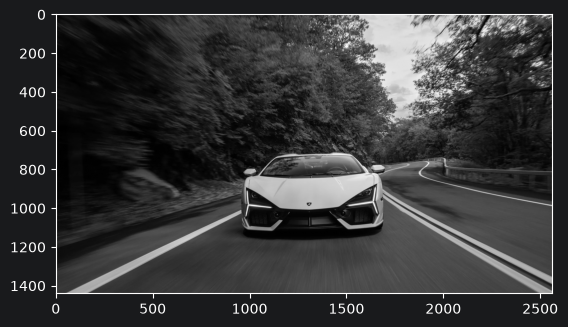

In [2]:
IMAGE_PATH = p.IMAGE_ASSETS / "lambo.jpg"

img = cv.imread(IMAGE_PATH)

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
plt.figure()
plt.imshow(gray, cmap="gray" )

(np.float64(-0.5), np.float64(2559.5), np.float64(1439.5), np.float64(-0.5))

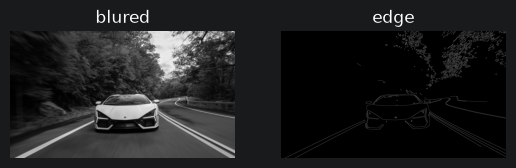

In [3]:
img_blur = cv.GaussianBlur(gray, (11, 11), 0)
canny_edge = cv.Canny(img_blur, 50, 150, apertureSize=3)

plt.figure()
plt.subplot(121)
plt.title("blured")
plt.imshow(img_blur, cmap="gray")
plt.axis("off")

plt.subplot(122)
plt.title("edge")
plt.imshow(canny_edge, cmap="gray")
plt.axis("off")

In [4]:
@dataclass(frozen=True)
class TBarNames:
    RHO: str = "rho"
    DEG: str = "degree"
    THRESHOLD: str = "threshold"
    K: str = "k"

In [5]:
def callback(value: int) -> None:
    pass

In [6]:
window_name = "hough line"
cv.namedWindow(window_name)

cv.createTrackbar(TBarNames.RHO, window_name, 100, 200, callback)
cv.setTrackbarMin(TBarNames.RHO, window_name, 1)
cv.createTrackbar(TBarNames.DEG, window_name, 180, 360, callback)
cv.setTrackbarMin(TBarNames.DEG, window_name, 1)
cv.createTrackbar(TBarNames.THRESHOLD, window_name, 150, 300, callback)
cv.createTrackbar(TBarNames.K, window_name, 200, 600, callback)

while True:
    if cv.waitKey(1) & 0xFF == ord('q'):
        break

    overlay = img.copy()

    rho = cv.getTrackbarPos(TBarNames.RHO, window_name) / 100.0

    degree = cv.getTrackbarPos(TBarNames.DEG, window_name)
    theta = np.pi / degree

    threshold = cv.getTrackbarPos(TBarNames.THRESHOLD, window_name)
    k = cv.getTrackbarPos(TBarNames.K, window_name) * 10


    lines = cv.HoughLines(canny_edge, rho, theta, threshold)

    if lines is not None:

        for l in lines:
            line_rho, theta = l[0]
            dhat = np.array([[np.cos(theta)], [np.sin(theta)]])
            d = line_rho * dhat
            lhat = np.array([[-np.sin(theta)], [np.cos(theta)]])

            p1 = (d + k * lhat).astype(int)
            p2 = (d - k * lhat).astype(int)

            cv.line(overlay,
                    (p1[0][0], p1[1][0]),
                    (p2[0][0], p2[1][0]),
                    (0, 255, 255),
                    5)



    text_data = f"rho: {rho:.2f} | theta: {theta:.2f} | threshold: {threshold} | k: {k:.2f}"
    cv.putText(overlay,
               text_data,
               (30, 30),
               fontFace=cv.FONT_HERSHEY_SIMPLEX,
               fontScale=1,
               color=(0, 255, 0),
               thickness=2)

    cv.imshow(window_name, overlay)

cv.destroyAllWindows()

